# Inner Sydney High, a deep dive: floor space per student

Inner Sydney High School (NSW school 8913, Surry Hills) is the exception in a land analysis. Divide a school's grounds
(the land it sits on, buildings included) by its students and most Sydney schools land in the tens of square metres;
this one lands in single figures. It is a 14-storey school on a small inner-city site, so the land figure says little
about the space the students have. This notebook asks the next question: how much floor space does each student have?

The shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com): the site from three NSW Cadastre lots,
the new building's podium and the four heritage buildings picked from OpenStreetMap outlines, and the tower's roof
outline drawn over the NSW aerial photo of 22 January 2021. Students are the NSW Department of Education's headcount,
one figure per year. The school opened in stages: Year 7 in 2020, a year group a year, Years 7 to 12 from 2025.

Floor space is **estimated**: each building's footprint times its storeys. It is checked against the gross floor area
(GFA) approved for the school (SSD 7610), quoted in `data/planning/`. The section "Read it carefully" says what the
estimate counts and how far to trust it.

It reads only the files in `../data`.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*colormapping.*')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Geod

DATA = '../data'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
# Plotlay's drafting-film colours
FILM, PAPER, INK, INK2, TEXT, MUTED, RED, TEAL, GOLD = '#f2efe6', '#faf8f1', '#1d4f91', '#163c6e', '#1f2a37', '#5b6573', '#cf3b26', '#2f9e8a', '#d9a21b'
RULE = (29 / 255, 79 / 255, 145 / 255, .35)
PART = {'New building': INK, 'Heritage building': TEAL}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'text.color': TEXT, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.edgecolor': RULE, 'figure.facecolor': FILM, 'axes.facecolor': FILM, 'savefig.facecolor': FILM,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlecolor': INK2, 'axes.titleweight': 'bold'})

## Sources and licence

School site: NSW Cadastre lots (DCS Spatial Services), CC BY 3.0 AU. Podium and heritage building outlines:
© OpenStreetMap contributors, ODbL 1.0, so `data/geometry/buildings.*` is under the ODbL 1.0. Tower outline: drawn over
NSW Imagery (DCS Spatial Services), CC BY 3.0 AU. Headcounts: NSW Department of Education, CC BY. Approved floor areas:
quoted from the NSW Planning Portal record for SSD 7610 (see `data/planning/README.md`). Our tables: CC BY 4.0. Full
credits are in `NOTICE`.

## Load

In [2]:
b = pd.read_csv(f'{DATA}/buildings/buildings.csv')
enr = pd.read_csv(f'{DATA}/site/enrolments.csv')
fiu = pd.read_csv(f'{DATA}/site/floor_in_use.csv')
roll = pd.read_csv(f'{DATA}/site/site_rollup.csv')
gfa = pd.read_csv(f'{DATA}/planning/approved_floor_areas.csv').set_index('component').m2
shapes = gpd.read_file(f'{DATA}/geometry/buildings.geojson')
site = gpd.read_file(f'{DATA}/geometry/school_site.geojson')
assert b.key.is_unique and set(b.key) == set(shapes.key)
print(len(b), 'buildings;', len(site), 'site shape from', len(roll.lots[0].split()), 'Cadastre lots;', enr.year.min(), 'to', enr.year.max(), 'headcounts')
b[['key', 'name', 'part', 'storeys', 'height_m', 'levels', 'in_use_from', 'outline_from', 'footprint_m2', 'floor_m2_est']]

6 buildings; 1 site shape from 3 Cadastre lots; 2020 to 2025 headcounts


,key,name,part,storeys,height_m,levels,in_use_from,outline_from,footprint_m2,floor_m2_est
0,P,"New building, podium",New building,6,16.9,"Basement, Lower Ground, Ground, Levels 1 to 3",2021,OpenStreetMap way/1178119661 (ODbL),2102.2,12613
1,T,"New building, tower",New building,8,48.3,Levels 4 to 11 (Level 4 mostly an open games t...,2021,"Drawn over NSW Imagery, 22 January 2021",993.6,7948
2,H1,Heritage building 1,Heritage building,3,12.0,3 storeys (OpenStreetMap),2020,OpenStreetMap way/570103244 (ODbL),653.2,1960
3,H2,Heritage building 2,Heritage building,2,8.0,2 storeys (OpenStreetMap),2020,OpenStreetMap way/570103245 (ODbL),448.9,898
4,H3,Heritage building 3,Heritage building,3,12.0,3 storeys (OpenStreetMap),2020,OpenStreetMap way/570103241 (ODbL),340.6,1022
5,H4,Heritage building 4,Heritage building,2,8.0,2 storeys (OpenStreetMap),2020,OpenStreetMap way/570103246 (ODbL),225.6,451


## The grounds

The site's area, worked out two ways: geodesic (on the GRS80 ellipsoid) and in GDA2020 Australian Albers (EPSG:9473), an
equal-area projection. (GDA2020 Lambert, EPSG:7845, is conformal and would not keep areas true.)

In [3]:
geod = Geod(ellps='GRS80')
site_geo = sum(abs(geod.geometry_area_perimeter(g)[0]) for g in site.geometry)
site_alb = site.to_crs(9473).geometry.area.sum()
grounds = site_alb
print(f'Grounds: {site_alb:,.1f} m² in EPSG:9473, {site_geo:,.1f} m² geodesic (difference {abs(site_alb / site_geo - 1):.4%})')
print(f'Plotlay worked out {site.area_m2.sum():,.1f} m²; the roll-up table says {roll.grounds_m2[0]:,.0f} m²')
hc = enr.set_index('year').students
last = hc.index.max()
print(f'{last}: {hc[last]:,} students, {grounds / hc[last]:.1f} m² of grounds each')

Grounds: 5,687.3 m² in EPSG:9473, 5,687.3 m² geodesic (difference 0.0000%)
Plotlay worked out 5,687.2 m²; the roll-up table says 5,687 m²
2025: 1,161 students, 4.9 m² of grounds each


That is the figure that makes the school the exception. In the Sydney schools showcase the median grounds per student in
2025 was 34.7 m² across 14 compared high schools and 30.3 m² across 49 primary schools. Those schools mostly sit on one
or two storeys over a playground; this one stacks 14 storeys on a small inner-city site. Land per student
measures how much ground a school has, not how much room its students have, so for a vertical school the useful figure is
floor space. The rest of this notebook works that out for this one school. It does not rank or compare its floor space
against any other school.

## The buildings

Six shapes. The new building is two of them: the podium **P** (the OpenStreetMap outline of the whole new building at
ground level, Basement to Level 3, 6 storeys) and the tower **T** (its roof outline, Levels 4 to 11, 8 storeys) drawn
on top of the podium. The four heritage buildings **H1** to **H4** are the former Cleveland Street school buildings,
refurbished, with their storeys from OpenStreetMap.

Standing on another shape: T on P


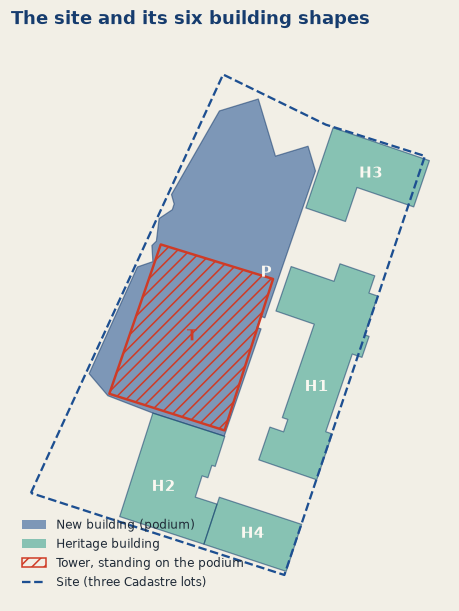

In [4]:
alb = shapes.to_crs(9473).set_index('key')
pts = site.to_crs(9473)
# which shapes stand on another one (most of their area inside it)
on = {k: [o for o in alb.index if o != k and alb.geometry[k].intersection(alb.geometry[o]).area > .8 * alb.geometry[k].area] for k in alb.index}
stacked = sorted(k for k, v in on.items() if v)
print('Standing on another shape:', ', '.join(f'{k} on {on[k][0]}' for k in stacked))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
pts.boundary.plot(ax=ax, color=INK, lw=1.5, ls='--')
for k, r in alb.join(b.set_index('key')[['part']]).iterrows():
    if k in stacked: continue
    gpd.GeoSeries([r.geometry]).plot(ax=ax, color=PART[r.part], alpha=.55, edgecolor=INK2, lw=.8)
for k in stacked:
    gpd.GeoSeries([alb.geometry[k]]).plot(ax=ax, facecolor='none', edgecolor=RED, lw=1.6, hatch='///')
for k, r in alb.iterrows():
    g = r.geometry
    for o in stacked:   # label a shape where nothing stands on it
        if k in on[o]: g = g.difference(alb.geometry[o])
    x, y = g.representative_point().coords[0]
    ax.annotate(k, (x, y), ha='center', va='center', fontsize=10, fontweight='bold', color=RED if k in stacked else PAPER)
ax.set_axis_off()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=PART['New building'], alpha=.55), plt.Rectangle((0, 0), 1, 1, fc=PART['Heritage building'], alpha=.55),
                   plt.Rectangle((0, 0), 1, 1, fc='none', ec=RED, hatch='///'), plt.Line2D([], [], color=INK, ls='--')],
          labels=['New building (podium)', 'Heritage building', 'Tower, standing on the podium', 'Site (three Cadastre lots)'], fontsize=8, loc='lower left', frameon=False)
ax.set_title('The site and its six building shapes', loc='left'); plt.show()

### Floor space, building by building (estimated)

Each building's floor estimate is its footprint times its storeys. The footprints are Plotlay's (`footprint_m2`); the
same shapes measured here in EPSG:9473 are shown beside them as a check.

Floor space, estimated: 24,893 m² (new building 20,562 m², heritage buildings 4,331 m²)


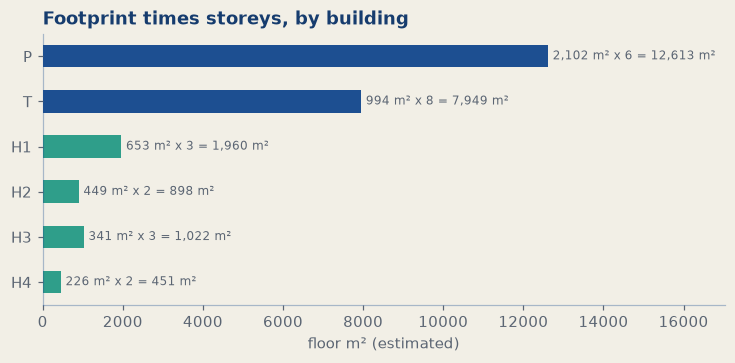

,key,footprint_m2,footprint_check_m2,storeys,floor_m2_est,floor_check_m2
0,P,2102.2,2102.2,6,12613,12613.0
1,T,993.6,993.6,8,7948,7949.0
2,H1,653.2,653.2,3,1960,1960.0
3,H2,448.9,448.9,2,898,898.0
4,H3,340.6,340.6,3,1022,1022.0
5,H4,225.6,225.6,2,451,451.0


In [5]:
b['footprint_check_m2'] = b.key.map(alb.geometry.area).round(1)
b['floor_check_m2'] = (b.footprint_m2 * b.storeys).round()
floor_total = b.floor_check_m2.sum()
new = b[b.part == 'New building'].floor_check_m2.sum(); her = b[b.part == 'Heritage building'].floor_check_m2.sum()
print(f'Floor space, estimated: {floor_total:,.0f} m² (new building {new:,.0f} m², heritage buildings {her:,.0f} m²)')
ax = b.set_index('key').floor_check_m2.plot.barh(color=b.part.map(PART), figsize=(8, 3.2)); ax.invert_yaxis()
for i, (v, s, f) in enumerate(zip(b.floor_check_m2, b.storeys, b.footprint_m2)): ax.text(v + 120, i, f'{f:,.0f} m² x {s} = {v:,.0f} m²', va='center', fontsize=8, color=MUTED)
ax.set_xlim(0, b.floor_check_m2.max() * 1.35); ax.set_xlabel('floor m² (estimated)'); ax.set_ylabel('')
ax.set_title('Footprint times storeys, by building', loc='left'); plt.show()
b[['key', 'footprint_m2', 'footprint_check_m2', 'storeys', 'floor_m2_est', 'floor_check_m2']]

### Rolled up to the site

The site's footprint counts the podium and the heritage buildings, not the tower again: the tower stands on the podium,
so its ground is already counted. Plotlay's roll-up of the shapes inside the site adds every shape, tower included; the
difference is the tower's footprint.

In [6]:
fp_site = b[~b.key.isin(stacked)].footprint_m2.sum()
fp_all = site.footprint_m2.sum()
print(f'Site footprint: {fp_site:,.0f} m², {fp_site / grounds:.0%} of the grounds (every shape added: {fp_all:,.1f} m², less the tower {b.set_index("key").footprint_m2[stacked].sum():,.1f} m²)')
print(f'Floor over grounds: {floor_total / grounds:.2f} (floor space, estimated, over the site area)')
print(f'Floor over the site footprint: {floor_total / fp_site:.2f}')

Site footprint: 3,770 m², 66% of the grounds (every shape added: 4,764.1 m², less the tower 993.6 m²)
Floor over grounds: 4.38 (floor space, estimated, over the site area)
Floor over the site footprint: 6.60


## Floor space per student, year by year

The heritage buildings were in use from 2020; the new building from Term 1 2021. Floor in use each year is the floor
estimate of the buildings in use that year. `data/site/floor_in_use.csv` carries the same figure from the plan; it is
compared below.

In [7]:
yrs = hc.index
use = pd.Series({y: b[b.in_use_from <= y].floor_check_m2.sum() for y in yrs}, name='floor_in_use_m2')
tbl = fiu.set_index('year').floor_in_use_m2_est
per = pd.DataFrame({'students': hc, 'year_groups': enr.set_index('year').year_groups, 'floor_in_use_m2': use,
                    'floor_in_use_table_m2': tbl, 'floor_per_student': (use / hc).round(1), 'grounds_per_student': (grounds / hc).round(1)})
print(f'Floor in use against the table: largest difference {(tbl / use - 1).abs().max():.2%}')
cap = int(roll.capacity[0])
print(f'At capacity ({cap:,} students): {floor_total / cap:.1f} m² of floor space each (estimated)')
per

Floor in use against the table: largest difference 0.02%
At capacity (1,200 students): 20.7 m² of floor space each (estimated)


,students,year_groups,floor_in_use_m2,floor_in_use_table_m2,floor_per_student,grounds_per_student
2020,147,Year 7,4331.0,4330,29.5,38.7
2021,358,Years 7 and 8,24893.0,24888,69.5,15.9
2022,591,Years 7 to 9,24893.0,24888,42.1,9.6
2023,797,Years 7 to 10,24893.0,24888,31.2,7.1
2024,999,Years 7 to 11,24893.0,24888,24.9,5.7
2025,1161,Years 7 to 12,24893.0,24888,21.4,4.9


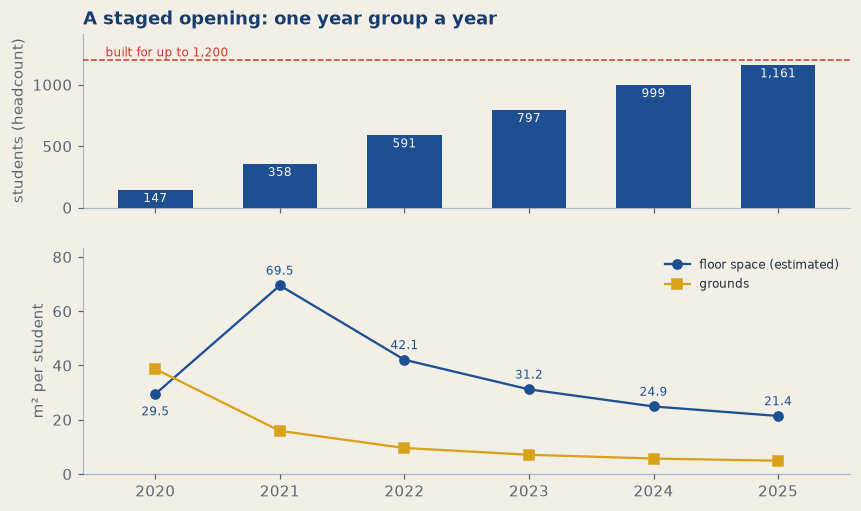

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={'height_ratios': [1, 1.3]})
ax[0].bar(per.index, per.students, color=INK, width=.6)
for y, v in per.students.items(): ax[0].text(y, v - 25, f'{v:,}', ha='center', va='top', fontsize=8, color=PAPER)
ax[0].axhline(cap, color=RED, lw=1, ls='--'); ax[0].text(per.index.min() - .4, cap + 30, f'built for up to {cap:,}', fontsize=8, color=RED)
ax[0].set_ylim(0, cap * 1.18); ax[0].set_ylabel('students (headcount)')
ax[1].plot(per.index, per.floor_per_student, color=INK, marker='o', label='floor space (estimated)')
ax[1].plot(per.index, per.grounds_per_student, color=GOLD, marker='s', label='grounds')
for y, v in per.floor_per_student.items(): ax[1].annotate(f'{v:.1f}', (y, v), textcoords='offset points', xytext=(0, -14 if per.grounds_per_student[y] > v else 7), ha='center', fontsize=8, color=INK)
ax[1].set_ylim(0, per.floor_per_student.max() * 1.2); ax[1].set_ylabel('m² per student'); ax[1].legend(frameon=False, fontsize=8)
ax[0].set_title('A staged opening: one year group a year', loc='left'); plt.show()

The 2021 peak is the staged opening, not a measure of comfort: the whole new building opened to two year groups. The
figure falls each year as a year group is added, and 2025 is the first year with all six.

## The estimate against the approved floor areas

The approved plans (SSD 7610, the GFA area schedule) list the gross floor area by part. GFA is measured from the inside
of the outer walls and leaves out stairs, lifts, plant and open areas; this schedule counts covered outdoor terraces as
GFA in their own line.

Approved GFA: 18,154.0 m² in all, of which 5,538.3 m² covered outdoor terraces; enclosed 12,615.7 m²
Estimate over approved GFA: 1.37 times the total, 1.97 times the enclosed GFA
New building: estimate 20,562 m² against 14,740.9 m² approved (enclosed and terraces), 1.39 times
Heritage buildings: estimate 4,331 m² against 3,413.1 m² approved, 1.27 times
2025, per student: 21.4 m² estimated; approved GFA 15.6 m² in all, 10.9 m² enclosed


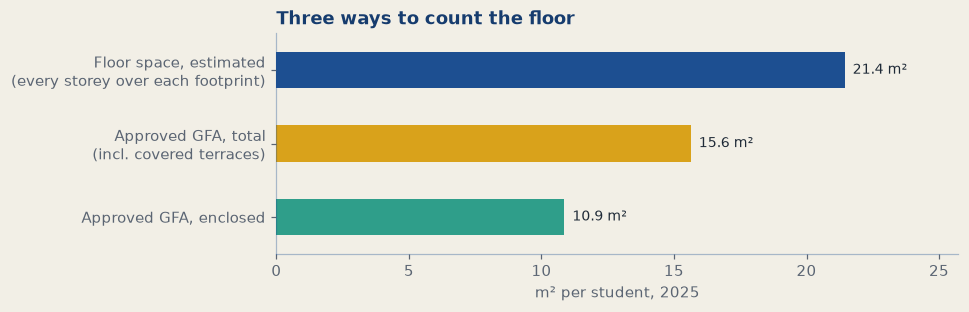

In [9]:
G = {'new': gfa['New building, enclosed GFA'], 'terraces': gfa['Covered outdoor terraces counted as GFA'], 'heritage': gfa['Heritage buildings 1 to 3, GFA'],
     'total': gfa['Total GFA on the schedule'], 'enclosed': gfa['Enclosed GFA (new and heritage), derived']}
y = last
print(f'Approved GFA: {G["total"]:,.1f} m² in all, of which {G["terraces"]:,.1f} m² covered outdoor terraces; enclosed {G["enclosed"]:,.1f} m²')
print(f'Estimate over approved GFA: {floor_total / G["total"]:.2f} times the total, {floor_total / G["enclosed"]:.2f} times the enclosed GFA')
print(f'New building: estimate {new:,.0f} m² against {G["new"] + G["terraces"]:,.1f} m² approved (enclosed and terraces), {new / (G["new"] + G["terraces"]):.2f} times')
print(f'Heritage buildings: estimate {her:,.0f} m² against {G["heritage"]:,.1f} m² approved, {her / G["heritage"]:.2f} times')
print(f'{y}, per student: {floor_total / hc[y]:.1f} m² estimated; approved GFA {G["total"] / hc[y]:.1f} m² in all, {G["enclosed"] / hc[y]:.1f} m² enclosed')
cmp = pd.Series({'Floor space, estimated\n(every storey over each footprint)': floor_total, 'Approved GFA, total\n(incl. covered terraces)': G['total'], 'Approved GFA, enclosed': G['enclosed']})
ax = (cmp / hc[y]).plot.barh(color=[INK, GOLD, TEAL], figsize=(8, 2.6)); ax.invert_yaxis()
for i, v in enumerate(cmp / hc[y]): ax.text(v + .3, i, f'{v:.1f} m²', va='center', fontsize=9)
ax.set_xlim(0, (cmp / hc[y]).max() * 1.2); ax.set_xlabel(f'm² per student, {y}')
ax.set_title('Three ways to count the floor', loc='left'); plt.show()

## Read it carefully

- **The method.** Floor space is each building's footprint times its storeys: a gross floor plate figure. It counts
  every storey over the whole footprint, including the open undercroft, covered and open terraces (Level 4 is mostly an
  open games terrace), stairs, lifts, plant rooms and the walls themselves. That is why it is larger than the approved
  GFA, by the ratios worked out above. Read it as an upper bound of the space
  students use; the approved enclosed GFA per student is the conservative figure.
- **The podium** uses the OpenStreetMap outline of the whole new building at ground level for all six of its storeys
  (Basement to Level 3). Floors that step in, and the basement's actual extent, are not known from the outline.
- **The tower** is a roof outline drawn over an aerial photo. A tall building is shown a little displaced in an aerial
  photo, so the outline is approximate; it is the figure most likely to move between runs, and a few per cent of its
  footprint is a few hundred square metres of floor over eight storeys.
- **The heritage buildings** take their storeys from OpenStreetMap (`building:levels`); their heights in the data are
  storeys times 4 m, an estimate. The approved schedule numbers three heritage buildings while OpenStreetMap draws four
  outlines, so the heritage comparison is approximate.
- **Students** are the February headcount, not full-time equivalent, for the school as a whole. Nothing here splits
  students across buildings.
- **Accuracy** depends on the drawings, imagery and outlines used. Where a figure has to stand up for a planning or
  contract purpose, use the approved plans and a measured survey.

## Checks

In [10]:
fps = (use / hc).round(1)
assert abs(site_alb / site_geo - 1) < .001, 'EPSG:9473 and geodesic areas agree'
assert abs(site_alb - roll.grounds_m2[0]) < 1.5 and abs(site_alb - site.area_m2.sum()) < 1.5, 'grounds as Plotlay worked them out'
assert stacked == ['T'] and on['T'] == ['P'], 'only the tower stands on another shape, the podium'
assert ((b.footprint_check_m2 / b.footprint_m2 - 1).abs() < .01).all(), 'footprints match the shapes'
assert ((b.floor_m2_est - b.floor_check_m2).abs() <= 1).all(), 'floor estimate is footprint times storeys'
assert 24500 <= floor_total <= 25600, floor_total
assert abs(floor_total - roll.floor_m2_est[0]) <= 1 and abs(fp_site - roll.footprint_m2[0]) <= 2, 'the site roll-up'
assert abs(fp_all - fp_site - b.set_index('key').footprint_m2['T']) < 2, 'every-shape roll-up less the tower'
assert list(yrs) == list(range(yrs.min(), yrs.max() + 1)) and hc[last] == roll.students_2025[0]
assert ((tbl / use - 1).abs() < .03).all(), 'the floor in use table'
assert 21 <= fps[2025] <= 22.2, fps[2025]
assert fps.idxmax() == 2021 and fps.loc[2021:].is_monotonic_decreasing, 'the staged opening'
assert abs(G['new'] + G['terraces'] + G['heritage'] - G['total']) < .2 and abs(G['new'] + G['heritage'] - G['enclosed']) < .2, 'the GFA schedule adds up'
assert G['enclosed'] < G['total'] < floor_total, 'the estimate counts more than the GFA'
print('All checks pass.')

All checks pass.
